In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay


In [59]:
df = pd.read_csv("/content/diabetes.csv")

In [60]:
df.shape

(768, 9)

In [61]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [63]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [64]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Outcome
0    500
1    268
Name: count, dtype: int64


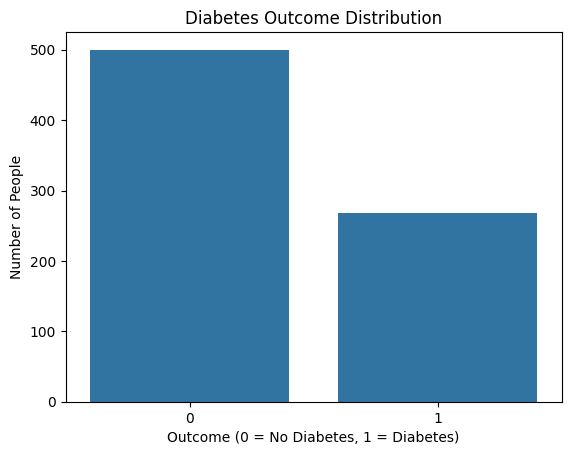

In [65]:

print(df["Outcome"].value_counts())
sns.countplot(x="Outcome", data=df)
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of People")
plt.show()

In [66]:
columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[columns] = df[columns].replace(0, np.nan)

In [67]:
print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [68]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

In [69]:
print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (768, 8)
Target (y): (768,)


In [70]:
print("\nInput Features:")
print(X.head())


Input Features:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0      NaN  33.6   
1            1     85.0           66.0           29.0      NaN  26.6   
2            8    183.0           64.0            NaN      NaN  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  


In [71]:
print("\nTarget Values:")
print(y.head())


Target Values:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [72]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [73]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Impute missing values using the median of each column
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# 2. Scale features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# 3. Fit the Logistic Regression model
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [74]:

y_pred = model.predict(X_test_scaled)
print("Predicted values:")
print(y_pred[:10])

Predicted values:
[1 0 0 0 0 0 1 1 0 1]


In [75]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7337662337662337

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154


Confusion Matrix:
[[75 25]
 [16 38]]


In [76]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.7337662337662337
Precision: 0.6031746031746031
Recall   : 0.7037037037037037
F1-score : 0.6495726495726496
ROC-AUC  : 0.8125925925925926


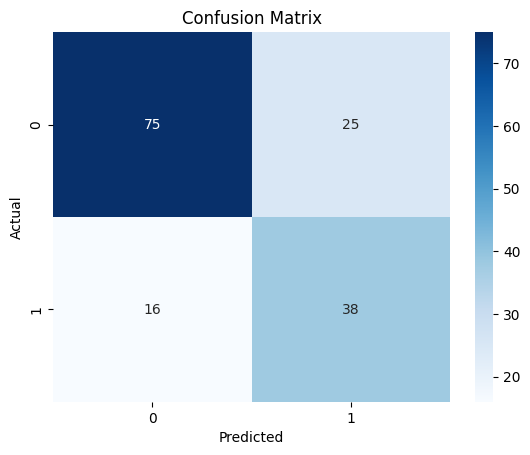

In [77]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

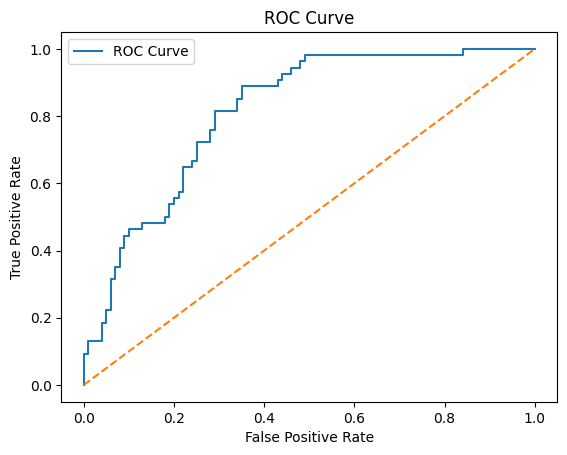

AUC Score: 0.8125925925925926


In [78]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label='ROC Curve')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print("AUC Score:", roc_auc_score(y_test, y_prob))

                    Feature  Coefficient
1                   Glucose     1.183483
5                       BMI     0.709592
0               Pregnancies     0.372902
6  DiabetesPedigreeFunction     0.287734
7                       Age     0.186434
3             SkinThickness     0.013980
2             BloodPressure    -0.014612
4                   Insulin    -0.044609


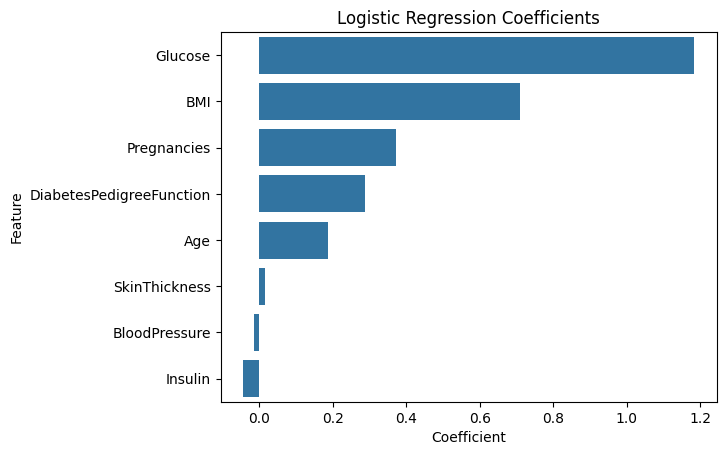

In [79]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
}).sort_values('Coefficient', ascending=False)
print(coef_df)

sns.barplot(x='Coefficient', y='Feature', data=coef_df)
plt.title('Logistic Regression Coefficients')
plt.show()

In [80]:
print("DIABETES PREDICTION MODEL")
print("-------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))

print("AUC Score:", roc_auc_score(y_test, y_prob))

print("\nModel: Logistic Regression")
print("Dataset: Diabetes.csv")
print("Training: 80%")
print("Testing: 20%")

DIABETES PREDICTION MODEL
-------------------------
Accuracy: 0.7337662337662337
AUC Score: 0.8125925925925926

Model: Logistic Regression
Dataset: Diabetes.csv
Training: 80%
Testing: 20%


In [81]:
# Prediction for a new patient
new_patient = pd.DataFrame([{
    'Pregnancies': 2,
    'Glucose': 150,
    'BloodPressure': 72,
    'SkinThickness': 35,
    'Insulin': 120,
    'BMI': 33.6,
    'DiabetesPedigreeFunction': 0.627,
    'Age': 45
}])


In [82]:
# 1. Impute and scale the new patient data using the already fitted imputer and scaler
new_patient_imputed = imputer.transform(new_patient)
new_patient_scaled = scaler.transform(new_patient_imputed)

# 2. Predict class and probability
prediction = model.predict(new_patient_scaled)[0]
probability = model.predict_proba(new_patient_scaled)[0][1]

print("NEW PATIENT PREDICTION")
print("----------------------")
print(new_patient.to_string(index=False))
print()
print("Predicted Outcome :", prediction)
print("Diabetes Probability: {:.2f}%".format(probability * 100))

if prediction == 1:
    print("Result: The model predicts DIABETES (Outcome = 1)")
else:
    print("Result: The model predicts NO DIABETES (Outcome = 0)")

NEW PATIENT PREDICTION
----------------------
 Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  BMI  DiabetesPedigreeFunction  Age
           2      150             72             35      120 33.6                     0.627   45

Predicted Outcome : 1
Diabetes Probability: 75.21%
Result: The model predicts DIABETES (Outcome = 1)


In [83]:
results = pd.DataFrame({
    'Actual': y_test.values[:10],
    'Predicted': y_pred[:10],
    'Diabetes_Probability': y_prob[:10].round(3)
})
print("Sample test predictions:")
print(results)

Sample test predictions:
   Actual  Predicted  Diabetes_Probability
0       0          1                 0.733
1       0          0                 0.212
2       0          0                 0.439
3       1          0                 0.383
4       0          0                 0.055
5       0          0                 0.281
6       1          1                 0.656
7       1          1                 0.962
8       0          0                 0.132
9       0          1                 0.907


## Conclusion

In this project, I built a Logistic Regression model to predict whether a person has diabetes, using the Pima Indians Diabetes dataset from Kaggle (768 records, 8 input features). Invalid zero values in Glucose, BloodPressure, SkinThickness, Insulin and BMI were treated as missing and filled with the median. The features were then scaled using StandardScaler. I used an 80/20 stratified train-test split and a class-balanced Logistic Regression model, because the dataset has more non-diabetic cases (500) than diabetic cases (268).

On the test data, the model achieved an accuracy of 0.734, precision of 0.603, recall of 0.704, F1-score of 0.650 and a ROC-AUC of 0.813. The confusion matrix shows 75 true negatives, 25 false positives, 16 false negatives and 38 true positives. This means the model correctly identified about 70% of the actual diabetic cases, and an AUC of 0.813 shows it separates the two classes reasonably well.

Recall is the most important metric here, because a false negative means a person with diabetes is missed. Using balanced class weights improved recall noticeably compared to the model without balancing, at the cost of some precision. For a screening-style task, I think this is a good trade-off.

The coefficients show that Glucose and BMI have the strongest positive effect on the prediction, so higher glucose levels and higher BMI increase the chance of the model predicting diabetes. This matches what is generally known about diabetes risk.

**Limitations:** The dataset is small and comes from a specific population, and many Insulin and SkinThickness values were missing and had to be imputed. The model is only suitable for learning classification concepts and should not be used for real medical diagnosis. Results could be improved in future by trying other models (such as Random Forest), tuning the decision threshold, and using more diverse data.